In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import drive
from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)


In [34]:
drive_path = Path("/content/drive/MyDrive")

if not drive_path.exists():
    print("Google Drive is not mounted.")
    drive.mount("/content/drive")

project_dir = drive_path / "Nexar_Project"

print("\nGoogle Drive connected:", drive_path.exists())
print("Project directory exists:", project_dir.exists())

if project_dir.exists():
    print("\nProject folders:")

    for item in sorted(project_dir.iterdir()):
        if item.is_dir():
            print(f"[DIR]  {item.name}")
        else:
            print(f"[FILE] {item.name}")

    for folder_name in ["positive", "negative"]:

        folder = project_dir / "Dataset_2FPS" / folder_name

        print(f"\nChecking: {folder}")
        print("Directory exists:", folder.exists())

        if folder.exists():
            files = list(folder.glob("*.npz"))
            print("NPZ files found:", len(files))

else:
    print("\nNexar_Project was not found in MyDrive.")


Google Drive connected: True
Project directory exists: True

Project folders:
[DIR]  Dataset_2FPS
[DIR]  Dataset_3FPS
[DIR]  Extracted_Features
[DIR]  Logs
[DIR]  Manifests
[DIR]  Metadata
[DIR]  Models
[DIR]  Public_Test

Checking: /content/drive/MyDrive/Nexar_Project/Dataset_2FPS/positive
Directory exists: True
NPZ files found: 750

Checking: /content/drive/MyDrive/Nexar_Project/Dataset_2FPS/negative
Directory exists: True
NPZ files found: 751


In [35]:
PROJECT_DIR = "/content/drive/MyDrive/Nexar_Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "Dataset_2FPS")

POSITIVE_DIR = os.path.join(DATASET_DIR, "positive")
NEGATIVE_DIR = os.path.join(DATASET_DIR, "negative")

MANIFEST_DIR = os.path.join(PROJECT_DIR, "Manifests")

TRAIN_MANIFEST = os.path.join(
    MANIFEST_DIR,
    "train_manifest.csv"
)

VAL_MANIFEST = os.path.join(
    MANIFEST_DIR,
    "validation_manifest.csv"
)

MODEL_DIR = os.path.join(PROJECT_DIR, "Models")

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_model_mobilenetv2_bigru_16frames.keras"
)

print("Project paths configured successfully.")

Project paths configured successfully.


In [36]:
required_paths = {
    "Project": PROJECT_DIR,
    "Positive Dataset": POSITIVE_DIR,
    "Negative Dataset": NEGATIVE_DIR,
    "Train Manifest": TRAIN_MANIFEST,
    "Validation Manifest": VAL_MANIFEST,
    "Best Model": BEST_MODEL_PATH
}

for name, path in required_paths.items():
    print(f"{name}: {os.path.exists(path)}")

Project: True
Positive Dataset: True
Negative Dataset: True
Train Manifest: True
Validation Manifest: True
Best Model: True


In [37]:
train_df = pd.read_csv(TRAIN_MANIFEST)

validation_df = pd.read_csv(VAL_MANIFEST)

# Support either label or target column
for df in [train_df, validation_df]:

    if "label" not in df.columns and "target" in df.columns:
        df.rename(columns={"target": "label"}, inplace=True)

    if "file_name" not in df.columns and "id" in df.columns:
        df["file_name"] = df["id"].astype(str)

    if "label" not in df.columns:
        raise ValueError("Manifest must contain label or target column.")

    if "file_name" not in df.columns:
        raise ValueError("Manifest must contain file_name or id column.")

print("Train samples:", len(train_df))
print("Validation samples:", len(validation_df))

print("\nTrain distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(validation_df["label"].value_counts())

Train samples: 1200
Validation samples: 300

Train distribution:
label
1    600
0    600
Name: count, dtype: int64

Validation distribution:
label
0    150
1    150
Name: count, dtype: int64


In [38]:
SEQUENCE_LENGTH = 16

IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3

BATCH_SIZE = 1

AUTOTUNE = tf.data.AUTOTUNE

print("Video configuration completed.")

Video configuration completed.


In [39]:
def prepare_video(npz_path, sequence_length=SEQUENCE_LENGTH):

    with np.load(npz_path) as data:

        frames = data["frames"]

    total_frames = len(frames)

    if total_frames == 0:
        raise ValueError(f"Empty video: {npz_path}")

    if total_frames >= sequence_length:

        indices = np.linspace(
            0,
            total_frames - 1,
            sequence_length
        ).astype(int)

        selected_frames = frames[indices]

        mask = np.ones(
            sequence_length,
            dtype=np.float32
        )

    else:

        selected_frames = np.zeros(
            (
                sequence_length,
                IMAGE_HEIGHT,
                IMAGE_WIDTH,
                CHANNELS
            ),
            dtype=np.uint8
        )

        selected_frames[:total_frames] = frames

        selected_frames[total_frames:] = frames[-1]

        mask = np.zeros(
            sequence_length,
            dtype=np.float32
        )

        mask[:total_frames] = 1.0

    return selected_frames.astype(np.float32), mask

In [40]:
def normalize_label(value):

    if isinstance(value, str):

        value = value.strip().lower()

        if value in ["positive", "pos", "1"]:
            return 1.0

        if value in ["negative", "neg", "0"]:
            return 0.0

    return float(value)


def resolve_npz_path(file_name, label):

    label = normalize_label(label)

    folder = POSITIVE_DIR if label == 1 else NEGATIVE_DIR

    file_stem = Path(str(file_name)).stem

    npz_path = os.path.join(folder, file_stem + ".npz")

    if not os.path.exists(npz_path):
        raise FileNotFoundError(
            f"NPZ file not found: {npz_path}"
        )

    return npz_path


def data_generator(dataframe, shuffle=False):

    df = dataframe.copy()

    if shuffle:
        df = df.sample(frac=1).reset_index(drop=True)

    for _, row in df.iterrows():

        npz_path = resolve_npz_path(
            row["file_name"],
            row["label"]
        )

        frames, mask = prepare_video(npz_path)
        mask = mask.astype(bool)

        label = normalize_label(row["label"])

        inputs = {
            "video_input": frames,
            "mask_input": mask
        }

        yield inputs, np.float32(label)

In [41]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_df, shuffle=True),
    output_signature=output_signature
)

validation_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(validation_df, shuffle=False),
    output_signature=output_signature
)

train_dataset = (
    train_dataset
    .repeat()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

validation_dataset = (
    validation_dataset
    .repeat()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Datasets recreated successfully.")

Datasets recreated successfully.


In [42]:
SEQUENCE_LENGTH = 16

IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3

BATCH_SIZE = 1
EPOCHS = 6

LEARNING_RATE = 1e-4

print("Training configuration completed.")

Training configuration completed.


In [43]:
from tensorflow.keras import layers, models, regularizers

# Video input
video_input = layers.Input(
    shape=(
        SEQUENCE_LENGTH,
        IMAGE_HEIGHT,
        IMAGE_WIDTH,
        CHANNELS
    ),
    name="video_input"
)

# Boolean mask input
mask_input = layers.Input(
    shape=(SEQUENCE_LENGTH,),
    dtype=tf.bool,
    name="mask_input"
)

# Resize and normalize frames
x = layers.TimeDistributed(
    layers.Resizing(160, 160),
    name="frame_resize"
)(video_input)

x = layers.TimeDistributed(
    layers.Rescaling(
        scale=1.0 / 127.5,
        offset=-1.0
    ),
    name="frame_normalization"
)(x)

# MobileNetV2 backbone
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(160, 160, 3)
)

base_model.trainable = False

# Extract features from each frame
x = layers.TimeDistributed(
    base_model,
    name="feature_extraction"
)(x)

x = layers.LayerNormalization(
    name="feature_normalization"
)(x)

# Bidirectional GRU
x = layers.Bidirectional(
    layers.GRU(
        32,
        dropout=0.15,
        recurrent_dropout=0.0,
        return_sequences=False
    ),
    name="bidirectional_gru"
)(
    x,
    mask=mask_input
)

# Temporal feature normalization
x = layers.LayerNormalization(
    name="temporal_normalization"
)(x)

# Classification head
x = layers.Dropout(0.30)(x)

x = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-5)
)(x)

x = layers.LayerNormalization()(x)

x = layers.Dropout(0.30)(x)

output = layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32",
    name="collision_prediction"
)(x)

# Build model
model = models.Model(
    inputs={
        "video_input": video_input,
        "mask_input": mask_input
    },
    outputs=output,
    name="MobileNetV2_BiGRU_16Frames"
)

model.summary()

Model: "MobileNetV2_BiGRU_16Frames"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ video_input         │ (None, 16, 224,   │          0 │ -                 │
│ (InputLayer)        │ 224, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frame_resize        │ (None, 16, 160,   │          0 │ video_input[0][0] │
│ (TimeDistributed)   │ 160, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ frame_normalization │ (None, 16, 160,   │          0 │ frame_resize[0][… │
│ (TimeDistributed)   │ 160, 3)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_extraction  │ (None, 16, 1280)  │  2,257,984 │ frame_normalizat… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_normalizat… │ (None, 16, 1280)  │      2,560 │ feature_extracti… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_input          │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_gru   │ (None, 64)        │    252,288 │ feature_normaliz… │
│ (Bidirectional)     │                   │            │ mask_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_normaliza… │ (None, 64)        │        128 │ bidirectional_gr… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ temporal_normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      4,160 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64)        │        128 │ dense_1[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ collision_predicti… │ (None, 1)         │         65 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,517,313 (9.60 MB)

 Trainable params: 259,329 (1013.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
os.makedirs(MODEL_DIR, exist_ok=True)

NEW_BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_model_mobilenetv2_bigru_16frames_new_run.keras"
)

CSV_LOG_PATH = os.path.join(
    MODEL_DIR,
    "training_history_16frames_new_run.csv"
)

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=NEW_BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        CSV_LOG_PATH
    )
]

print("Callbacks configured successfully.")

Callbacks configured successfully.


In [24]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="binary_crossentropy",

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [26]:
history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    steps_per_epoch=len(train_df),

    validation_data=validation_dataset,
    validation_steps=len(validation_df),

    callbacks=callbacks,

    verbose=1
)

Epoch 1/6
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 918ms/step - accuracy: 0.5628 - auc: 0.5990 - loss: 0.7801 - precision: 0.5621 - recall: 0.5325
Epoch 1: val_loss improved from None to 0.47059, saving model to /content/drive/MyDrive/Nexar_Project/Models/best_model_mobilenetv2_bigru_16frames_new_run.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Nexar_Project/Models/best_model_mobilenetv2_bigru_16frames_new_run.keras
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1498s 1s/step - accuracy: 0.6092 - auc: 0.6721 - loss: 0.7047 - precision: 0.6143 - recall: 0.5867 - val_accuracy: 0.7833 - val_auc: 0.8611 - val_loss: 0.4706 - val_precision: 0.8058 - val_recall: 0.7467 - learning_rate: 1.0000e-04
Epoch 2/6


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_loss did not improve from 0.47059
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 170s 142ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.0000e+00 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.7833 - val_auc: 0.8611 - val_loss: 0.4706 - val_precision: 0.8058 - val_recall: 0.7467 - learning_rate: 1.0000e-04
Epoch 3/6
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 0s 638ms/step - accuracy: 0.7483 - auc: 0.8148 - loss: 0.5406 - precision: 0.7376 - recall: 0.7622
Epoch 3: val_loss improved from 0.47059 to 0.41442, saving model to /content/drive/MyDrive/Nexar_Project/Models/best_model_mobilenetv2_bigru_16frames_new_run.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Nexar_Project/Models/best_model_mobilenetv2_bigru_16frames_new_run.keras
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 951s 783ms/step - accuracy: 0.7408 - auc: 0.8112 - loss: 0.5454 - precision: 0.7373 - recall: 0.7483 - val_accuracy: 0.8167 - val_auc: 0.9052 - val_loss: 0.4144 - val_precision: 0.7714 - val_recall: 0.

In [27]:
FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_model_mobilenetv2_bigru_16frames_new_run.keras"
)

model.save(FINAL_MODEL_PATH)

print("Final model saved successfully.")

Final model saved successfully.


In [28]:
train_results = model.evaluate(
    train_dataset,
    steps=len(train_df),
    verbose=1,
    return_dict=True
)

print("\nTrain Evaluation Results:")

for metric, value in train_results.items():

    print(f"{metric}: {value:.4f}")

1200/1200 ━━━━━━━━━━━━━━━━━━━━ 704s 586ms/step - accuracy: 0.8933 - auc: 0.9652 - loss: 0.2488 - precision: 0.8722 - recall: 0.9217

Train Evaluation Results:
accuracy: 0.8933
auc: 0.9652
loss: 0.2488
precision: 0.8722
recall: 0.9217


In [29]:
validation_results = model.evaluate(
    validation_dataset,
    steps=len(validation_df),
    verbose=1,
    return_dict=True
)

print("\nValidation Evaluation Results:")

for metric, value in validation_results.items():

    print(f"{metric}: {value:.4f}")

300/300 ━━━━━━━━━━━━━━━━━━━━ 172s 573ms/step - accuracy: 0.8400 - auc: 0.9204 - loss: 0.3644 - precision: 0.8493 - recall: 0.8267

Validation Evaluation Results:
accuracy: 0.8400
auc: 0.9204
loss: 0.3644
precision: 0.8493
recall: 0.8267


In [30]:
comparison_df = pd.DataFrame({

    "Train": train_results,

    "Validation": validation_results

})

comparison_df["Difference"] = (
    comparison_df["Train"] -
    comparison_df["Validation"]
)

print(comparison_df.round(4))

            Train  Validation  Difference
accuracy   0.8933      0.8400      0.0533
auc        0.9652      0.9204      0.0448
loss       0.2488      0.3644     -0.1155
precision  0.8722      0.8493      0.0229
recall     0.9217      0.8267      0.0950


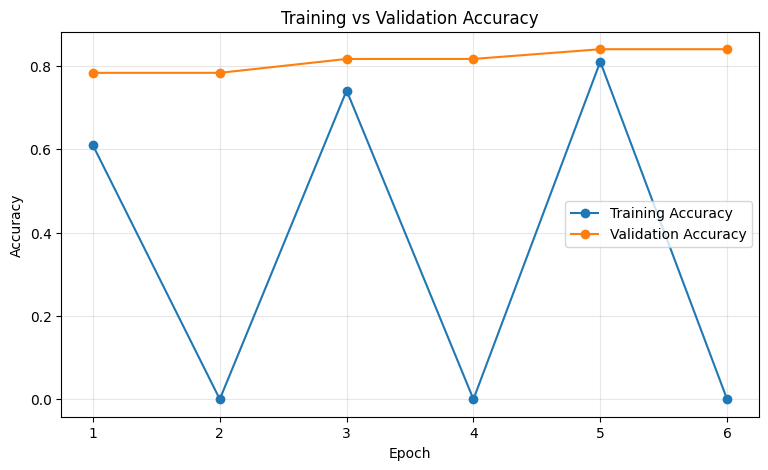

In [31]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()